# Q2 Student Pathways — School and Combination Option Benchmark

**Group Achille-Sylvie** · Cishahayo Songa Achille, Umwiza Sylvie · Question 2

## What this notebook produces

A model-ready dataset for the Student Pathways Advisory Unit (SPAU). The
raw folder now holds public Rwanda school-level extracts.

**One row = one school × one A-level subject combination (or TVET trade)
offered in the 2023/24 NESA results.** The target is
`alevel_avg_pct_2023_24`, the school's average A-level percentage for that
combination.

## Why the unit of analysis changed

Tis notebook builds the school and combination benchmark that a later student-level recommender will use to
score options. It answers *"how does this option typically perform?"* — not
*"how will this student score?"*. Step 6 explains how the benchmark is
meant to feed the recommendation.

## How to read the notebook

Every step follows the same shape:

1. **What you are looking at** — the table or question for that step.
2. **How it works** — the rules and the reason for them.
3. The code and its output.
4. **Reading the output** — what the numbers mean and what to check.

Run from top to bottom in a clean kernel. The fixed seed is 42.

## Step 1 — Verify the environment and inventory the raw files

### What you are looking at

The Q2 raw folder now holds four public school-level extracts. There are no
simulated student records in this workflow.

| File | What it holds | Role in the analysis |
| --- | --- | --- |
| `rwanda_alevel_school_choice_dataset_RAW_MERGED.csv` | One row per school × A-level subject combination offered in 2023/24, with school context, results, and TVET accreditation fields | Core analytic table |
| `nesa_rankings_2023_24_parsed_long.csv` | Long-format NESA 2023/24 rankings: O-level plus 15 A-level sections, with rank and average percentage | Source used to verify the merged results |
| `wda_tvet_schools_2020_21_parsed.csv` | WDA 2020/21 list of accredited TVET schools and their trades | Source behind the TVET fields |
| `combination_to_ranking_category_map.csv` | Maps each combination code to the NESA ranking section it is ranked in | Programme grouping |

### How it works

The cell prints the library versions, then reads each raw file just far enough
to record its number of rows and columns and a SHA-256 fingerprint. The
fingerprint is a short audit trail: if someone replaces a raw file, the
fingerprint changes and the run is no longer the one documented here.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import hashlib
import platform

import matplotlib
import numpy as np
import pandas as pd
import sklearn
from src.q2_config import COMBINATION_MAP_FILE, NESA_FILE, RAW_FILE, WDA_FILE

def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(8192), b''):
            digest.update(block)
    return digest.hexdigest()

print('Python:', platform.python_version())
print('pandas:', pd.__version__, '| numpy:', np.__version__)
print('scikit-learn:', sklearn.__version__, '| matplotlib:', matplotlib.__version__)

inventory = []
for role, path in [
    ('core analytic table', RAW_FILE),
    ('NESA A-level and O-level rankings', NESA_FILE),
    ('WDA TVET accreditation list', WDA_FILE),
    ('combination -> ranking section map', COMBINATION_MAP_FILE),
]:
    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    inventory.append({
        'role': role,
        'file': path.name,
        'rows': frame.shape[0],
        'columns': frame.shape[1],
        'sha256 (first 12)': sha256(path)[:12],
    })

display(pd.DataFrame(inventory))

Python: 3.14.6
pandas: 3.0.3 | numpy: 2.4.6
scikit-learn: 1.9.0 | matplotlib: 3.11.0


,role,file,rows,columns,sha256 (first 12)
0,core analytic table,rwanda_alevel_school_choice_dataset_RAW_MERGED...,1278,31,9de2f7ae9ea2
1,NESA A-level and O-level rankings,nesa_rankings_2023_24_parsed_long.csv,4470,6,6033b0537bb0
2,WDA TVET accreditation list,wda_tvet_schools_2020_21_parsed.csv,192,10,460632ac4515
3,combination -> ranking section map,combination_to_ranking_category_map.csv,51,2,e735ad428457


### Reading the output

The core table has 1,278 offer rows and 31 columns; the ranking and
accreditation tables are supporting sources with 4,470 and 192 rows. The
hashes should be quoted in the source log when the work is submitted.

## Step 2 — Load and document the analytic table

Group Achille-Sylvie | Members: Cishahayo Songa Achille, Umwiza Sylvie | Question: Q2 | Stage: 2: acquisition and schema documentation

## Step 2 — Load and document the analytic table

### What you are looking at

Each row is **one offer**: a school paired with one subject combination or
TVET trade in the 2023/24 NESA A-level results. A school with five
combinations contributes five rows. The target is the school's average
A-level percentage for that combination, not an individual student's score.

The 31 columns fall into six groups:

- **Identity and geography** — `district`, `district_code`, `sector`,
  `sector_code`, `school_name`, `school_code`.
- **School context** — `school_category` (General Education, TVET, TTC,
  Professional Education, Nine-Twelve YBE, Special Needs).
- **Programme choice** — `combination_code`, `combination_name`,
  `gender_intake`, `ranking_category`.
- **A-level outcome** — `alevel_avg_pct_2023_24` (the target),
  `alevel_rank_in_category`, `alevel_n_schools_in_category`.
- **Prior O-level performance** — `olevel_avg_pct_2023_24`,
  `olevel_rank_national`, `olevel_n_schools_ranked`.
- **Provenance and TVET attributes** — the `nesa_*` and `wda_*` fields.

### How it works

`load_raw` reads every column as text. That is deliberate: school codes keep
leading zeros, and quality problems such as blank cells or odd labels stay
visible instead of being silently converted. The cell then writes a data
dictionary that names each column's meaning and role.

Three definitions matter for the rest of the notebook:

1. `alevel_avg_pct_2023_24` is the **school × combination average** in the
   NESA A-level table. It is not a student-level outcome.
2. `olevel_avg_pct_2023_24` is the same school's O-level average for a
   **different cohort**. It was published before students chose A-level
   options, so it is a legitimate prior-performance feature.
3. `ranking_category` is the NESA section in which the school is ranked
   (for example `GE_SCIENCE` or `TSS_CONSTRUCTION`). It is known from the
   chosen programme, not from the result.

In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date

import pandas as pd
from src.q2_config import DOCS_DIR, RAW_FILE
from src.q2_pipeline import load_raw

DOCS_DIR.mkdir(parents=True, exist_ok=True)
raw = load_raw(RAW_FILE)

print('path:', RAW_FILE)
print('shape:', raw.shape)
display(raw.head(3))

entries = [
    ('district', 'Geography', 'District where the school is located', 'Feature'),
    ('district_code', 'Geography', 'Official district code', 'Identifier'),
    ('sector', 'Geography', 'Sector where the school is located; finer than district', 'Identifier'),
    ('sector_code', 'Geography', 'Official sector code', 'Identifier'),
    ('school_name', 'Identity', 'School name as published in the source', 'Identifier'),
    ('school_code', 'Identity', 'Unique school code used to join the source tables', 'Identifier'),
    ('school_category', 'School context', 'General Education, TVET, TTC, Professional Education, Nine-Twelve YBE, or Special Needs', 'Feature'),
    ('combination_code', 'Programme', 'Code of the A-level combination or TVET trade', 'Feature'),
    ('combination_name', 'Programme', 'Full name of the combination or trade', 'Descriptive'),
    ('gender_intake', 'Programme', 'Mixed or single-sex intake policy', 'Feature'),
    ('boarding_note', 'School context', 'Free-text boarding note; only two offers have one', 'Descriptive'),
    ('ranking_category', 'Programme', 'NESA ranking section the school is ranked in', 'Feature and stratification group'),
    ('alevel_avg_pct_2023_24', 'A-level outcome', 'Average A-level percentage for this school and combination in 2023/24', 'Target'),
    ('alevel_rank_in_category', 'A-level outcome', 'Rank of the school within its NESA section', 'Leakage'),
    ('alevel_n_schools_in_category', 'A-level outcome', 'Number of schools ranked in that NESA section', 'Leakage'),
    ('olevel_avg_pct_2023_24', 'Prior O-level results', 'School average O-level percentage in 2023/24', 'Feature'),
    ('olevel_rank_national', 'Prior O-level results', 'School national O-level rank', 'Feature'),
    ('olevel_n_schools_ranked', 'Prior O-level results', 'Number of schools in the national O-level ranking (constant 1,871)', 'Used only to derive rank percent'),
    ('nesa_name_in_alevel_table', 'Provenance', 'School name in the NESA A-level table, where matched', 'Identifier'),
    ('wda_sn', 'WDA provenance', 'Row number in the WDA TVET list', 'Identifier'),
    ('wda_match_score', 'WDA provenance', 'Fuzzy-match confidence between school and WDA record', 'Identifier'),
    ('wda_match_method', 'WDA provenance', 'How the WDA record was matched', 'Identifier'),
    ('wda_school_name', 'WDA provenance', 'School name in the WDA list', 'Identifier'),
    ('wda_province', 'WDA provenance', 'Province in the WDA list', 'Identifier'),
    ('wda_district', 'WDA provenance', 'District in the WDA list', 'Identifier'),
    ('wda_sector', 'WDA provenance', 'Sector in the WDA list', 'Identifier'),
    ('wda_status', 'School context', 'Ownership label for a WDA-listed school (many raw spellings)', 'Descriptive'),
    ('wda_n_accredited_trades', 'School context', 'Number of accredited trades offered', 'Feature'),
    ('wda_accredited_trades', 'School context', 'Names of accredited trades', 'Descriptive'),
    ('wda_accredited_levels', 'School context', 'Accredited levels for the trades', 'Descriptive'),
    ('wda_non_accredited', 'School context', 'Trades listed but not accredited', 'Descriptive'),
]
dictionary = pd.DataFrame(entries, columns=['column', 'group', 'description', 'role'])
assert len(dictionary) == raw.shape[1], 'every raw column must be documented'
dictionary.to_csv(DOCS_DIR / 'data_dictionary.csv', index=False)
(DOCS_DIR / 'data_dictionary.md').write_text(
    '# Q2 Data Dictionary\n\n' + dictionary.to_string(index=False) + '\n'
)
display(dictionary)

path: /home/songa/Documents/CODING/CLASS WORK/ML-Learning/q2_own_scenario/data/raw/rwanda_alevel_school_choice_dataset_RAW_MERGED.csv
shape: (1278, 31)


,district,district_code,sector,sector_code,school_name,school_code,school_category,combination_code,combination_name,gender_intake,...,wda_match_method,wda_school_name,wda_province,wda_district,wda_sector,wda_status,wda_n_accredited_trades,wda_accredited_trades,wda_accredited_levels,wda_non_accredited
0,Nyarugenge,11,Kanyinya,1102,TVET KANYINYA,110206,TVET,FAD,Fashion Design,MIXED,...,auto_fuzzy_name+district,Kanyinya TVET School,Kigali City,Nyarugenge,Kanyinya,Gov.Aided,3,Automobile Engine Mechanics; Masonry; Tailoring,"3; 3,4",
1,Nyarugenge,11,Kanyinya,1102,TVET KANYINYA,110206,TVET,AUT,Automobile Technology,MIXED,...,auto_fuzzy_name+district,Kanyinya TVET School,Kigali City,Nyarugenge,Kanyinya,Gov.Aided,3,Automobile Engine Mechanics; Masonry; Tailoring,"3; 3,4",
2,Nyarugenge,11,Kanyinya,1102,TVET KANYINYA,110206,TVET,BDC,Building Construction,MIXED,...,auto_fuzzy_name+district,Kanyinya TVET School,Kigali City,Nyarugenge,Kanyinya,Gov.Aided,3,Automobile Engine Mechanics; Masonry; Tailoring,"3; 3,4",


,column,group,description,role
0,district,Geography,District where the school is located,Feature
1,district_code,Geography,Official district code,Identifier
2,sector,Geography,Sector where the school is located; finer than...,Identifier
3,sector_code,Geography,Official sector code,Identifier
4,school_name,Identity,School name as published in the source,Identifier
5,school_code,Identity,Unique school code used to join the source tables,Identifier
6,school_category,School context,"General Education, TVET, TTC, Professional Edu...",Feature
7,combination_code,Programme,Code of the A-level combination or TVET trade,Feature
8,combination_name,Programme,Full name of the combination or trade,Descriptive
9,gender_intake,Programme,Mixed or single-sex intake policy,Feature


### Reading the output

Check that every raw column appears once in the dictionary and that
`alevel_avg_pct_2023_24` is marked **Target**, while the two rank columns are
marked **Leakage**. Those two columns are computed from the same A-level
results, so using them as inputs would hand the model the answer.

The source log records where the table came from and how it was checked.

In [3]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date

import pandas as pd
from src.q2_config import DOCS_DIR, RAW_FILE
from src.q2_pipeline import load_raw

raw = load_raw(RAW_FILE)
target_available = pd.to_numeric(raw['alevel_avg_pct_2023_24'], errors='coerce').notna().sum()
offers = len(raw)
schools = raw['school_code'].nunique()

source_log = '\n'.join([
    '# Q2 Source Log',
    '',
    '## Core analytic table',
    '',
    '- **File:** `' + RAW_FILE.name + '`',
    '- **Rows and columns:** ' + str(offers) + ' offers and ' + str(raw.shape[1]) + ' columns, covering ' + str(schools) + ' schools.',
    '- **Unit of analysis:** one school x one A-level subject combination (or TVET trade) in the 2023/24 NESA results.',
    '- **Target:** `alevel_avg_pct_2023_24`, available for ' + str(target_available) + ' of ' + str(offers) + ' offers.',
    '- **Source description:** school-level NESA 2023/24 A-level and O-level rankings, merged with the WDA 2020/21 accredited TVET school list using the supplied school codes and names.',
    '- **Provenance checks:** the target and O-level values match `nesa_rankings_2023_24_parsed_long.csv` exactly on `school_code` and NESA section (maximum absolute difference 0.00).',
    '- **Access date used in this run:** ' + date.today().isoformat() + '.',
    '',
    '## Supporting tables',
    '',
    '- `nesa_rankings_2023_24_parsed_long.csv`: long-format NESA 2023/24 rankings (O-level and 15 A-level sections).',
    '- `wda_tvet_schools_2020_21_parsed.csv`: WDA 2020/21 accredited TVET schools and trades.',
    '- `combination_to_ranking_category_map.csv`: maps combination codes to NESA ranking sections.',
    '',
    '## Limits and disclosure',
    '',
    '- The WDA list is from 2020/21 while the NESA results are from 2023/24; accreditation may have changed.',
    '- No student-level records, names, phone numbers, national IDs, or precise home locations are present.',
    '- This is public school-level evidence. It supports an option-level benchmark, not a guarantee about an individual student.',
    '- Confirm the NESA/REB and WDA publication licence terms and access URLs with the lecturer before submission; this log records file-level provenance only.',
])
(DOCS_DIR / 'source_log.md').write_text(source_log + '\n')
print(source_log)

# Q2 Source Log

## Core analytic table

- **File:** `rwanda_alevel_school_choice_dataset_RAW_MERGED.csv`
- **Rows and columns:** 1278 offers and 31 columns, covering 339 schools.
- **Unit of analysis:** one school x one A-level subject combination (or TVET trade) in the 2023/24 NESA results.
- **Target:** `alevel_avg_pct_2023_24`, available for 1225 of 1278 offers.
- **Source description:** school-level NESA 2023/24 A-level and O-level rankings, merged with the WDA 2020/21 accredited TVET school list using the supplied school codes and names.
- **Provenance checks:** the target and O-level values match `nesa_rankings_2023_24_parsed_long.csv` exactly on `school_code` and NESA section (maximum absolute difference 0.00).
- **Access date used in this run:** 2026-11-12.

## Supporting tables

- `nesa_rankings_2023_24_parsed_long.csv`: long-format NESA 2023/24 rankings (O-level and 15 A-level sections).
- `wda_tvet_schools_2020_21_parsed.csv`: WDA 2020/21 accredited TVET schools and trades.

In [4]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from src.q2_config import NESA_FILE, RAW_FILE, TARGET
from src.q2_pipeline import load_raw

# Join the long NESA table back to the merged offers and compare the two
# outcomes directly. If the merge had mis-assigned a school or section,
# this difference would not be zero.
raw = load_raw(RAW_FILE)
nesa = pd.read_csv(NESA_FILE, dtype=str)
alevel_rows = nesa.loc[nesa['section'] != 'O_LEVEL', ['school_code', 'section', 'avg_pct']]
olevel_rows = nesa.loc[nesa['section'] == 'O_LEVEL', ['school_code', 'avg_pct']]

target_check = raw.merge(
    alevel_rows, left_on=['school_code', 'ranking_category'],
    right_on=['school_code', 'section'], how='left',
)
olevel_check = raw.merge(olevel_rows, on='school_code', how='left')

target_diff = (
    pd.to_numeric(target_check[TARGET], errors='coerce')
    - pd.to_numeric(target_check['avg_pct'], errors='coerce')
).abs()
olevel_diff = (
    pd.to_numeric(olevel_check['olevel_avg_pct_2023_24'], errors='coerce')
    - pd.to_numeric(olevel_check['avg_pct'], errors='coerce')
).abs()

print('A-level offers matched back to NESA:', int(target_check['avg_pct'].notna().sum()))
print('maximum target difference:', round(float(target_diff.max()), 2))
print('O-level records matched back to NESA:', int(olevel_check['avg_pct'].notna().sum()))
print('maximum O-level difference:', round(float(olevel_diff.max()), 2))

A-level offers matched back to NESA: 1225
maximum target difference: 0.0
O-level records matched back to NESA: 671
maximum O-level difference: 0.0


### Reading the output

Every one of the 1,225 target values joins back to the NESA long table with
a maximum difference of zero, and so do the 671 O-level records. That makes
the merged target traceable to the published ranking rather than to an
unexplained calculation.

The 53 unmatched offers are the ones with no target: they do not appear in
the NESA A-level table. They stay in the raw file and are dropped later only
because a supervised row needs an outcome.

## Step 3 — Audit data quality and coverage

Group Achille-Sylvie | Members: Cishahayo Songa Achille, Umwiza Sylvie | Question: Q2 | Stage: 3: EDA and quality audit

## Step 3 — Audit data quality and coverage

### What you are looking at

Twelve checks answer three questions:

1. **Is each row unique and usable?** Exact duplicates, duplicate school ×
   combination rows, missing targets, and target outliers.
2. **Where are values missing, and why?** O-level, WDA, and boarding fields.
3. **Are labels consistent and safe?** WDA ownership spellings, constant
   columns, combination codes without a ranking section, and columns that
   reveal the target.

### How it works

The audit reads the raw table and changes nothing. Each check becomes one row
in a quality report with a severity and a proposed treatment.

The key interpretation is that **most missingness here is structural, not a
data-entry accident**:

- `olevel_*` is missing for TTCs and many TVET schools because those schools
  are not in the O-level ranking table.
- `wda_*` is missing for schools that are not on the WDA accredited TVET list.
- `alevel_avg_pct_2023_24` is missing when the school × combination does not
  appear in the NESA A-level table.

Deleting or blindly imputing those rows would erase the fact that TVET and
TTC options are measured differently. The cleaning step keeps flags instead.

,problem,columns_affected,records_affected,severity,proposed_treatment
0,Exact duplicate rows,all columns,0,High,Remove identical rows
1,Duplicate school x combination rows,"school_code, combination_code",0,High,Keep one offer row
2,Offers without the A-level target,alevel_avg_pct_2023_24,53,High,Drop; cannot supervise them
3,Offers without an O-level record,"olevel_avg_pct_2023_24, olevel_rank_national",607,Medium,Keep; add has_olevel_record flag
4,Offers without a WDA record,wda_sn and other wda_* fields,817,Medium,Keep; add has_wda_record flag
5,Offers without a boarding note,boarding_note,1276,Low,Exclude the field; too sparse to model
6,WDA ownership spellings,wda_status,13,Medium,Map to Public / Private
7,Columns derived from the target,"alevel_rank_in_category, alevel_n_schools_in_c...",2,High,Exclude from model inputs
8,Constant columns,olevel_n_schools_ranked,1,Low,Drop after deriving rank percent
9,Combination codes without a ranking section,combination_code,0,High,Investigate before modelling


,offers,with_target,with_olevel,with_wda,target_coverage_%
school_category,,,,,
General Education,521,517,518,22,99.2
NINE_TWELVE_YBE_ESI,4,4,4,0,100.0
NINE_TWELVE_YBE_GS,7,6,7,0,85.7
Professional Education,63,57,23,39,90.5
SPECIAL_NEEDS_EDUCATION_SCHOOL,5,5,3,0,100.0
TTC,59,59,0,0,100.0
TVET,619,577,116,400,93.2


,offers,with_target,mean_pct,median_pct
ranking_category,,,,
GE_SCIENCE,461,461,61.63,61.46
TSS_CONSTRUCTION,184,175,77.49,77.95
TSS_ICT_MULTIMEDIA,136,131,71.15,70.75
TSS_ENERGY,60,56,69.98,69.42
PE_TTC,59,59,69.37,67.87
TSS_HOSPITALITY_TOURISM,55,52,70.53,70.37
TSS_BUSINESS,55,50,74.35,74.88
GE_HUMANITIES,52,49,73.87,73.85
TSS_AGRICULTURE_FOOD,49,49,65.80,66.64


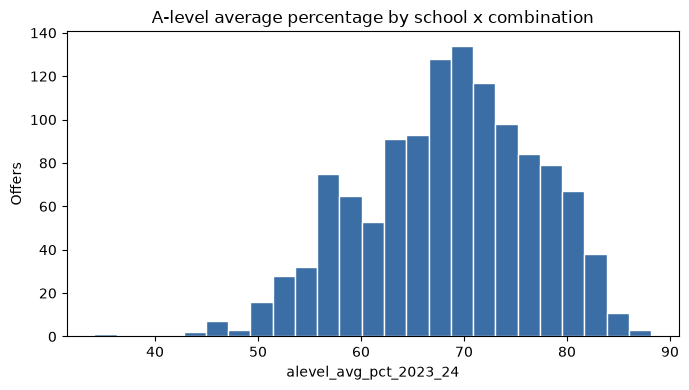

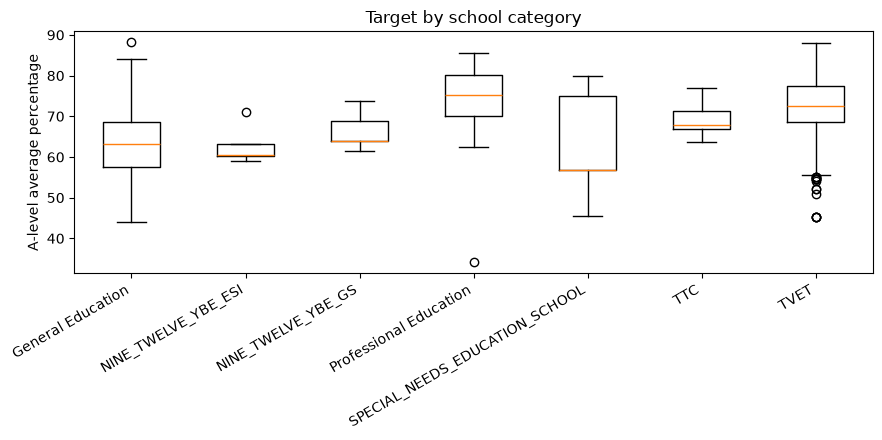

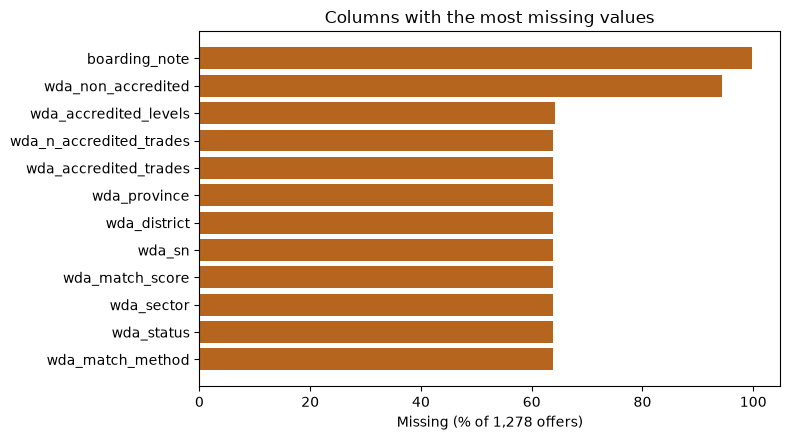

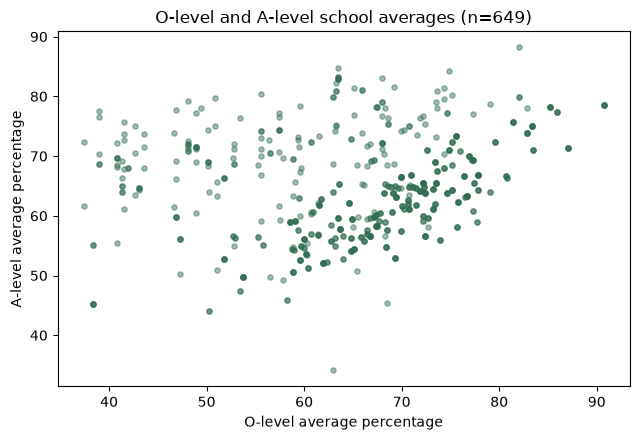

constant columns: ['olevel_n_schools_ranked']
unmapped combination codes: []


In [5]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.q2_config import (
    COMBINATION_MAP_FILE, DOCS_DIR, FIGURE_DIR, LEAKAGE_COLUMNS, RAW_FILE, TARGET,
)
from src.q2_pipeline import load_raw

DOCS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
raw = load_raw(RAW_FILE)
blank = raw.replace('', np.nan)
target = pd.to_numeric(blank[TARGET], errors='coerce')

q1, q3 = target.quantile([0.25, 0.75])
iqr = q3 - q1
outliers = int(((target < q1 - 1.5 * iqr) | (target > q3 + 1.5 * iqr)).sum())
constant_columns = [
    column for column in raw.columns
    if blank[column].notna().any() and blank[column].nunique(dropna=True) == 1
]
map_codes = set(pd.read_csv(COMBINATION_MAP_FILE, dtype=str)['combination_code'])
unmapped = sorted(set(raw['combination_code']) - map_codes)

issues = [
    ('Exact duplicate rows', 'all columns', int(raw.duplicated().sum()), 'High', 'Remove identical rows'),
    ('Duplicate school x combination rows', 'school_code, combination_code', int(raw.duplicated(['school_code', 'combination_code']).sum()), 'High', 'Keep one offer row'),
    ('Offers without the A-level target', TARGET, int(target.isna().sum()), 'High', 'Drop; cannot supervise them'),
    ('Offers without an O-level record', 'olevel_avg_pct_2023_24, olevel_rank_national', int(blank['olevel_avg_pct_2023_24'].isna().sum()), 'Medium', 'Keep; add has_olevel_record flag'),
    ('Offers without a WDA record', 'wda_sn and other wda_* fields', int(blank['wda_sn'].isna().sum()), 'Medium', 'Keep; add has_wda_record flag'),
    ('Offers without a boarding note', 'boarding_note', int(blank['boarding_note'].isna().sum()), 'Low', 'Exclude the field; too sparse to model'),
    ('WDA ownership spellings', 'wda_status', int(blank['wda_status'].nunique()), 'Medium', 'Map to Public / Private'),
    ('Columns derived from the target', ', '.join(LEAKAGE_COLUMNS), len(LEAKAGE_COLUMNS), 'High', 'Exclude from model inputs'),
    ('Constant columns', ', '.join(constant_columns) or 'none', len(constant_columns), 'Low', 'Drop after deriving rank percent'),
    ('Combination codes without a ranking section', 'combination_code', len(unmapped), 'High', 'Investigate before modelling'),
    ('Target values outside 1.5 x IQR', TARGET, outliers, 'Low', 'Keep; report rather than clip'),
    ('School names with repeated internal spaces', 'school_name', int(raw['school_name'].str.contains('  ', regex=False).sum()), 'Low', 'Collapse whitespace'),
]
quality = pd.DataFrame(issues, columns=['problem', 'columns_affected', 'records_affected', 'severity', 'proposed_treatment'])
quality.to_csv(DOCS_DIR / 'q2_data_quality_report.csv', index=False)
(DOCS_DIR / 'q2_data_quality_report.md').write_text(
    '# Q2 Data Quality Report\n\n' + quality.to_string(index=False) + '\n'
)
display(quality)

coverage = pd.DataFrame({
    'offers': raw.groupby('school_category').size(),
    'with_target': blank.assign(_t=target).groupby('school_category')['_t'].count(),
    'with_olevel': blank.assign(_o=blank['olevel_avg_pct_2023_24'].notna()).groupby('school_category')['_o'].sum(),
    'with_wda': blank.assign(_w=blank['wda_sn'].notna()).groupby('school_category')['_w'].sum(),
})
coverage['target_coverage_%'] = (100 * coverage['with_target'] / coverage['offers']).round(1)
display(coverage)

programme_summary = (
    blank.assign(_t=target)
    .groupby('ranking_category')
    .agg(offers=('_t', 'size'), with_target=('_t', 'count'),
         mean_pct=('_t', 'mean'), median_pct=('_t', 'median'))
    .sort_values('offers', ascending=False)
    .round(2)
)
display(programme_summary)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(target.dropna(), bins=25, color='#3b6ea5', edgecolor='white')
ax.set_title('A-level average percentage by school x combination')
ax.set_xlabel('alevel_avg_pct_2023_24')
ax.set_ylabel('Offers')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'q2_target_distribution.png', dpi=120)
display(fig)
plt.close(fig)

categories = coverage.index.tolist()
groups = [target[raw['school_category'] == category].dropna() for category in categories]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(groups)
ax.set_xticks(range(1, len(categories) + 1), categories, rotation=30, ha='right')
ax.set_title('Target by school category')
ax.set_ylabel('A-level average percentage')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'q2_target_by_school_category.png', dpi=120)
display(fig)
plt.close(fig)

missing_pct = (blank.isna().mean() * 100).sort_values(ascending=False).head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(missing_pct.index, missing_pct.values, color='#b5651d')
ax.set_title('Columns with the most missing values')
ax.set_xlabel('Missing (% of 1,278 offers)')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'q2_missingness.png', dpi=120)
display(fig)
plt.close(fig)

paired = pd.DataFrame({
    'olevel': pd.to_numeric(blank['olevel_avg_pct_2023_24'], errors='coerce'),
    'alevel': target,
}).dropna()
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(paired['olevel'], paired['alevel'], s=14, alpha=0.45, color='#2f6b4f')
ax.set_title('O-level and A-level school averages (n=' + str(len(paired)) + ')')
ax.set_xlabel('O-level average percentage')
ax.set_ylabel('A-level average percentage')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'q2_olevel_vs_alevel.png', dpi=120)
display(fig)
plt.close(fig)

print('constant columns:', constant_columns)
print('unmapped combination codes:', unmapped)

### Reading the output

- **Rows:** 1,278 offers, 339 schools, 30 districts, and 51 combination codes.
  The median school contributes four offers.
- **Target:** 1,225 offers have an A-level average, ranging from about 34 to 88
  with a mean near 68. The 53 without a target are mostly TVET and a few
  General Education offers that do not appear in the NESA A-level table.
- **Structural missingness:** O-level values exist for almost all General
  Education offers but for no TTC offer and only a minority of TVET offers. WDA fields
  are the mirror image: they cover TVET and some Professional Education
  schools, not General Education. This is why the next step adds coverage
  flags rather than dropping those rows.
- **Labels:** `wda_status` has 13 spellings of two meanings (public and
  private) and must be normalised. There are no exact duplicates and no
  duplicate school × combination rows.
- **Programme mix matters:** the programme summary ranks the 15 NESA sections.
  `GE_SCIENCE` is the largest section (461 offers) with a mean near 61.6, while
  `TSS_CONSTRUCTION` (175 offers) averages near 77.5. That does not mean TVET
  is "better"; the sections are marked on different populations. The model
  must therefore know the programme family, and the split must preserve it.
- **Coverage limits:** boarding information is present for only two offers, so
  boarding cannot be a feature here. The same applies to fees, distance, and
  facilities, which are not in this extract.

Four charts are saved to `q2_own_scenario/figures/`: the target distribution,
the target by school category, missingness, and the O-level/A-level
relationship. The last one shows a positive association, which supports
using prior O-level performance as a feature.

## Step 4 — Clean the table and log every decision

Group Achille-Sylvie | Members: Cishahayo Songa Achille, Umwiza Sylvie | Question: Q2 | Stage: 4: cleaning and preprocessing

## Step 4 — Clean the table and log every decision

### What you are looking at

The cleaned table is the same 31 columns, with values made consistent and 53
unusable offers removed. The raw CSV is not edited. The cleaning log records
each rule, how many values it touched, and the before/after shape.

### How it works

`clean_raw` applies these rules in order:

1. Trim outer whitespace and collapse repeated spaces inside school names;
   title-case district names.
2. Turn blank strings and placeholders (`n/a`, `unknown`, `none`, …) into
   proper missing values.
3. Parse percentages, ranks, and counts as numbers, even when the source
   stored them as text.
4. Set impossible values to missing: percentages outside 0–100, ranks below 1,
   negative trade counts.
5. Map the 13 WDA ownership spellings to `Public` or `Private`.
6. Map school and intake labels to readable categories.
7. Remove exact duplicates, then keep one row per school × combination.
8. Drop rows without the target or the school/combination key.

Missing O-level or WDA values are **not** imputed here. They stay missing and
are handled later by the training-fitted imputer, with coverage flags
preserving the reason they were absent.

In [6]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from src.logging_utils import CleaningLog
from src.q2_config import DOCS_DIR, INTERIM_DIR, RAW_FILE, TARGET
from src.q2_pipeline import clean_raw, load_raw

INTERIM_DIR.mkdir(parents=True, exist_ok=True)
raw = load_raw(RAW_FILE)
cleaning_log = CleaningLog()
cleaned = clean_raw(raw, cleaning_log)

cleaned.to_csv(INTERIM_DIR / 'q2_clean.csv', index=False)
cleaning_log.save(DOCS_DIR / 'cleaning_log.csv', DOCS_DIR / 'cleaning_log.md')

print('raw shape:', raw.shape)
print('cleaned shape:', cleaned.shape)
print('rows removed:', len(raw) - len(cleaned))
display(cleaning_log.to_df())
display(cleaned[[
    'school_name', 'district', 'school_category', 'combination_code',
    'ranking_category', 'wda_status', TARGET,
]].head(8))
print(cleaned['wda_status'].value_counts(dropna=False).to_string())

raw shape: (1278, 31)
cleaned shape: (1225, 31)
rows removed: 53


,step,columns,rule,n_affected,before,after,justification
0,strip_whitespace,all text columns,trim leading and trailing spaces,0,"(1278, 31)","(1278, 31)",avoid false label variants caused by stray spaces
1,normalise_names,"school_name,district",collapse internal spaces; title-case district,23,"(1278, 31)","(1278, 31)",one consistent label per school and district
2,set_missing_tokens,all text columns,empty and placeholder text -> missing,13505,"(1278, 31)","(1278, 31)",distinguish genuinely absent values from text ...
3,parse_numeric,"alevel_avg_pct_2023_24,alevel_rank_in_category...",extract numbers from text,0,"(1278, 31)","(1278, 31)",allow arithmetic and range checks
4,invalid_range,alevel_avg_pct_2023_24,"values outside [0, 100] -> missing",0,"(1278, 31)","(1278, 31)","remove impossible percentages, ranks, or counts"
5,invalid_range,olevel_avg_pct_2023_24,"values outside [0, 100] -> missing",0,"(1278, 31)","(1278, 31)","remove impossible percentages, ranks, or counts"
6,invalid_range,alevel_rank_in_category,"values outside [1, inf] -> missing",0,"(1278, 31)","(1278, 31)","remove impossible percentages, ranks, or counts"
7,invalid_range,olevel_rank_national,"values outside [1, inf] -> missing",0,"(1278, 31)","(1278, 31)","remove impossible percentages, ranks, or counts"
8,invalid_range,wda_n_accredited_trades,"values outside [0, inf] -> missing",0,"(1278, 31)","(1278, 31)","remove impossible percentages, ranks, or counts"
9,normalize_wda_status,wda_status,map ownership spellings to Public/Private,189,"(1278, 31)","(1278, 31)",one label per ownership meaning


,school_name,district,school_category,combination_code,ranking_category,wda_status,alevel_avg_pct_2023_24
0,TVET KANYINYA,Nyarugenge,TVET,AUT,TSS_TRANSPORT_LOGISTICS,Public,80.05
1,TVET KANYINYA,Nyarugenge,TVET,BDC,TSS_CONSTRUCTION,Public,83.64
2,TVET KANYINYA,Nyarugenge,TVET,FAD,TSS_CRAFT_ARTS,Public,75.88
3,COLLEGE DE BUTAMWA,Nyarugenge,General Education,HEG,GE_HUMANITIES,NaN,81.08
4,COLLEGE DE BUTAMWA,Nyarugenge,General Education,HGL,GE_HUMANITIES,NaN,81.08
5,COLLEGE DE BUTAMWA,Nyarugenge,General Education,LFK,GE_LANGUAGES,NaN,73.83
6,COLLEGE DE BUTAMWA,Nyarugenge,General Education,MPG,GE_SCIENCE,NaN,65.38
7,COLLEGE SAINT ANDRE,Nyarugenge,General Education,MCB,GE_SCIENCE,NaN,75.07


wda_status
NaN        784
Public     264
Private    177


### Reading the output

The step removes 53 offers without a target and changes no row count for
duplicates (there were none). The log should show the label fixes: two
ownership meanings now replace the raw spellings, and school names have
consistent spacing.

A useful check is that `q2_clean.csv` still has one row per school ×
combination and that every row has a target. The raw file is untouched, so
the quality report from Step 3 remains reproducible.

## Step 5 — Engineer features and separate leakage

Group Achille-Sylvie | Members: Cishahayo Songa Achille, Umwiza Sylvie | Question: Q2 | Stage: 5: feature engineering and leakage control

## Step 5 — Engineer features and separate leakage

### What you are looking at

Fourteen candidate inputs describe the option **before** its 2023/24 A-level
result is known:

| Feature | Built from | Why it is available at decision time |
| --- | --- | --- |
| `province` | `district` via the official district map | Coarse location is known |
| `district` | Raw district | Families choose within travel range |
| `school_category` | Raw category | School type is public information |
| `combination_code` | Raw code | The student is choosing it |
| `ranking_category` | Combination → NESA section | Programme family is known |
| `gender_intake` | Raw intake label | Published admission policy |
| `olevel_avg_pct_2023_24` | Prior O-level results | Published before A-level choice |
| `olevel_rank_national` | Prior national rank | Published before A-level choice |
| `olevel_rank_pct` | Rank ÷ 1,871 | Normalised version of the rank |
| `has_olevel_record` | O-level value present | Records whether the school is ranked at O-level |
| `has_wda_record` | WDA row present | Records whether the school is on the WDA list |
| `wda_n_accredited_trades` | WDA count, 0 if absent | Accreditation breadth is known |
| `wda_ownership` | Normalised WDA status | Public/private ownership of listed schools |
| `n_combinations_at_school` | Count of offers per school | Programme breadth is known |

### What is deliberately excluded

- **Target leakage:** `alevel_rank_in_category` and
  `alevel_n_schools_in_category` are computed from the 2023/24 A-level
  results. They would reveal the target's position and must never be inputs.
- **Identifiers and provenance:** `school_code`, `school_name`,
  `nesa_name_in_alevel_table`, the `wda_*` match fields, `sector`, and codes.
  Some carry no signal; `sector` is finer than district and acts as a
  location proxy, so it is excluded on privacy grounds.
- **Unusable or duplicate text:** `boarding_note` (two records),
  `combination_name` (duplicate of the code), and the free-text trade lists.

### A limitation to state clearly

This dataset has **no student-level grades, fees, distance, boarding
availability, or facilities**. It can benchmark how an option typically
performs; it cannot predict how a particular student will do. Step 6 explains
how the benchmark is meant to feed the SPAU recommendation.

In [7]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from src.q2_config import DOCS_DIR, ID_COLUMNS, LEAKAGE_COLUMNS, RAW_FILE, TARGET
from src.q2_pipeline import add_features, clean_raw, load_raw

features = add_features(clean_raw(load_raw(RAW_FILE)))
created = pd.DataFrame([
    ('province', 'district mapped to one of five provinces', 'Coarse location known before choice'),
    ('district', 'raw district', 'School location known before choice'),
    ('school_category', 'raw school category', 'School type is public information'),
    ('combination_code', 'raw combination code', 'The programme the student is choosing'),
    ('ranking_category', 'combination-to-section map', 'Programme family is known'),
    ('gender_intake', 'raw intake label', 'Published admission policy'),
    ('olevel_avg_pct_2023_24', 'prior O-level results', 'Published before A-level choice'),
    ('olevel_rank_national', 'prior national O-level rank', 'Published before A-level choice'),
    ('olevel_rank_pct', 'rank divided by 1,871 schools', 'Normalised prior rank'),
    ('has_olevel_record', 'O-level value present', 'Records structural missingness'),
    ('has_wda_record', 'WDA row present', 'Records whether the school is WDA-listed'),
    ('wda_n_accredited_trades', 'WDA trade count; 0 when not listed', 'Accreditation breadth'),
    ('wda_ownership', 'normalised WDA status; Not listed when absent', 'Ownership of listed schools'),
    ('n_combinations_at_school', 'distinct offers per school', 'Programme breadth'),
], columns=['feature', 'created from', 'why it is available at decision time'])
display(created)

excluded = [column for column in ID_COLUMNS if column in features.columns]
candidate_features = [
    column for column in features.columns
    if column not in set(ID_COLUMNS + LEAKAGE_COLUMNS + [TARGET])
]
print('candidate features (' + str(len(candidate_features)) + '):')
print(candidate_features)
print('\nexcluded identifiers and provenance (' + str(len(excluded)) + '):')
print(excluded)
print('\nexcluded target leakage:', LEAKAGE_COLUMNS)

display(features[[
    'school_name', 'combination_code', 'district', 'province',
    'olevel_avg_pct_2023_24', 'olevel_rank_pct', 'has_olevel_record',
    'has_wda_record', 'wda_n_accredited_trades', 'n_combinations_at_school',
]].head(8))

excluded_rows = [
    ('alevel_rank_in_category', 'Rank computed from the target within the NESA section', 'Leakage'),
    ('alevel_n_schools_in_category', 'Section size computed from the same results', 'Leakage'),
    ('school_code, school_name', 'Direct identifiers', 'Identifier'),
    ('nesa_name_in_alevel_table', 'Name matched from the NESA table', 'Provenance'),
    ('wda_sn, wda_match_score, wda_match_method', 'Record linkage fields', 'Provenance'),
    ('wda_school_name, wda_province, wda_district, wda_sector', 'Duplicates of known location/identity', 'Provenance'),
    ('district_code, sector_code, sector', 'Location identifiers; sector is finer than district', 'Identifier/privacy'),
    ('boarding_note', 'Only two offers have a note', 'Unusable'),
    ('combination_name', 'Duplicate text of combination_code', 'Redundant'),
    ('wda_accredited_trades, wda_accredited_levels, wda_non_accredited', 'Free-text trade lists', 'Descriptive'),
]
justification = pd.DataFrame([
    {'feature': row[0], 'definition': row[1], 'decision': row[2]}
    for row in created.itertuples(index=False)
] + [
    {'feature': name, 'definition': reason, 'decision': decision}
    for name, reason, decision in excluded_rows
])
(DOCS_DIR / 'feature_justification.md').write_text(
    '# Q2 Feature Justification\n\n' + justification.to_string(index=False) + '\n'
)
display(justification)

,feature,created from,why it is available at decision time
0,province,district mapped to one of five provinces,Coarse location known before choice
1,district,raw district,School location known before choice
2,school_category,raw school category,School type is public information
3,combination_code,raw combination code,The programme the student is choosing
4,ranking_category,combination-to-section map,Programme family is known
5,gender_intake,raw intake label,Published admission policy
6,olevel_avg_pct_2023_24,prior O-level results,Published before A-level choice
7,olevel_rank_national,prior national O-level rank,Published before A-level choice
8,olevel_rank_pct,"rank divided by 1,871 schools",Normalised prior rank
9,has_olevel_record,O-level value present,Records structural missingness


candidate features (14):
['district', 'school_category', 'combination_code', 'gender_intake', 'ranking_category', 'olevel_avg_pct_2023_24', 'olevel_rank_national', 'wda_n_accredited_trades', 'province', 'has_olevel_record', 'olevel_rank_pct', 'has_wda_record', 'wda_ownership', 'n_combinations_at_school']

excluded identifiers and provenance (19):
['school_code', 'school_name', 'district_code', 'sector', 'sector_code', 'combination_name', 'nesa_name_in_alevel_table', 'wda_sn', 'wda_match_score', 'wda_match_method', 'wda_school_name', 'wda_province', 'wda_district', 'wda_sector', 'wda_status', 'wda_accredited_trades', 'wda_accredited_levels', 'wda_non_accredited', 'boarding_note']

excluded target leakage: ['alevel_rank_in_category', 'alevel_n_schools_in_category']


,school_name,combination_code,district,province,olevel_avg_pct_2023_24,olevel_rank_pct,has_olevel_record,has_wda_record,wda_n_accredited_trades,n_combinations_at_school
0,TVET KANYINYA,AUT,Nyarugenge,Kigali City,NaN,NaN,0,1,3.0,3
1,TVET KANYINYA,BDC,Nyarugenge,Kigali City,NaN,NaN,0,1,3.0,3
2,TVET KANYINYA,FAD,Nyarugenge,Kigali City,NaN,NaN,0,1,3.0,3
3,COLLEGE DE BUTAMWA,HEG,Nyarugenge,Kigali City,65.97,0.069482,1,0,0.0,4
4,COLLEGE DE BUTAMWA,HGL,Nyarugenge,Kigali City,65.97,0.069482,1,0,0.0,4
5,COLLEGE DE BUTAMWA,LFK,Nyarugenge,Kigali City,65.97,0.069482,1,0,0.0,4
6,COLLEGE DE BUTAMWA,MPG,Nyarugenge,Kigali City,65.97,0.069482,1,0,0.0,4
7,COLLEGE SAINT ANDRE,MCB,Nyarugenge,Kigali City,83.37,0.003741,1,0,0.0,5


,feature,definition,decision
0,province,district mapped to one of five provinces,Coarse location known before choice
1,district,raw district,School location known before choice
2,school_category,raw school category,School type is public information
3,combination_code,raw combination code,The programme the student is choosing
4,ranking_category,combination-to-section map,Programme family is known
5,gender_intake,raw intake label,Published admission policy
6,olevel_avg_pct_2023_24,prior O-level results,Published before A-level choice
7,olevel_rank_national,prior national O-level rank,Published before A-level choice
8,olevel_rank_pct,"rank divided by 1,871 schools",Normalised prior rank
9,has_olevel_record,O-level value present,Records structural missingness


### Reading the output

The candidate list should contain exactly the 14 features in the table. The
two leakage columns must appear only in the excluded list. If a column name
is unfamiliar, check the data dictionary from Step 2 before adding it.

The O-level features are the strongest prior-performance signal. The coverage
flags are not tricks: they tell the model that a missing O-level record means
"not in the O-level ranking", which is itself informative about the school
type. The final model-ready file still imputes the missing numeric values from
the training median, as Step 6 shows.

## Step 6 — Split, encode, and finalise outputs

Group Achille-Sylvie | Members: Cishahayo Songa Achille, Umwiza Sylvie | Question: Q2 | Stage: 6: split, encode, and finalise outputs

## Step 6 — Split, encode, and write the model-ready files

### What you are looking at

Three files — train, validation, and test — each containing:

- seven readable key columns (`school_code`, `school_name`,
  `combination_code`, `combination_name`, `district`, `ranking_category`,
  `school_category`),
- the target `alevel_avg_pct_2023_24`,
- the secondary label `high_performer`,
- the encoded model inputs.

### How it works

1. **Split 70/15/15** with seed 42, stratified on `ranking_category`.
   Categories with fewer than 15 offers are pooled into `OTHER_RARE` for the
   split only, so every partition keeps a similar programme mix.
2. **Fit preprocessing on the training split only.** Median imputation and
   standard scaling for numeric columns; most-frequent imputation and
   one-hot encoding for categorical columns. Validation and test are only
   transformed with those fitted values.
3. **Define `high_performer`** as the top third of the training target. The
   threshold is computed on train and then applied unchanged to validation
   and test.
4. **Verify before writing:** no leakage columns, no missing values, identical
   columns across splits, and split sizes that add up to the cleaned table.

### Why this order matters

If the imputer, scaler, encoder, or threshold saw validation or test values,
the reported results would be optimistic. Splitting first and fitting on
train only is the minimum defence against that.

In [8]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import joblib
import pandas as pd
from src.q2_config import DOCS_DIR, LEAKAGE_COLUMNS, PROCESSED_DIR, RAW_FILE, TARGET
from src.q2_pipeline import load_raw, prepare_dataset

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
cleaned, train, validation, test, encoded, labels, transformer = prepare_dataset(load_raw(RAW_FILE))

outputs = {}
for name, encoded_split in encoded.items():
    output = encoded_split.copy()
    output[TARGET] = labels[name][TARGET].to_numpy()
    output['high_performer'] = labels[name]['high_performer'].to_numpy()
    output.to_csv(PROCESSED_DIR / ('q2_' + name + '_model_ready.csv'), index=False)
    outputs[name] = output

joblib.dump(transformer, PROCESSED_DIR / 'q2_preprocessor.joblib')
threshold = train[TARGET].quantile(2 / 3)

print('split sizes:', len(train), len(validation), len(test))
print('train-only high performer threshold:', round(float(threshold), 2))
print('encoded model inputs:', len(transformer.get_feature_names_out()))
print('total columns per model-ready file:', outputs['train'].shape[1])
print('leakage columns excluded:', LEAKAGE_COLUMNS)

expected_columns = list(outputs['train'].columns)
for name, output in outputs.items():
    assert not set(LEAKAGE_COLUMNS).intersection(output.columns), 'leakage in ' + name
    assert not output.isna().any().any(), 'missing values in ' + name
    assert list(output.columns) == expected_columns, 'column mismatch in ' + name
    assert output[TARGET].between(0, 100).all(), 'target out of range in ' + name
    assert set(output['high_performer'].unique()) <= {0, 1}, 'bad label in ' + name
assert len(train) + len(validation) + len(test) == len(cleaned), 'split does not cover cleaned rows'
print('verification checks passed')

display(outputs['train'].head(3))

card = '\n'.join([
    '# Q2 Data Card',
    '',
    '- **Purpose:** model-ready benchmark of A-level performance by school x subject combination for the Student Pathways Advisory Unit.',
    '- **Data status:** public school-level NESA 2023/24 and WDA 2020/21 extracts. No synthetic or student-level records are used.',
    '- **Rows:** ' + str(len(cleaned)) + ' school x combination offers after cleaning.',
    '- **Split:** train=' + str(len(train)) + ', validation=' + str(len(validation)) + ', test=' + str(len(test)) + ', stratified on programme family with seed 42.',
    '- **Target:** `' + TARGET + '`, the school-combination average A-level percentage (0-100).',
    '- **Secondary label:** `high_performer`, top third of the training target; threshold = ' + str(round(float(threshold), 2)) + '.',
    '- **Leakage excluded:** `alevel_rank_in_category` and `alevel_n_schools_in_category`.',
    '- **Known issues:** 53 offers lack a target; O-level records are missing for TTCs and many TVET schools; WDA coverage is partial; boarding notes are almost absent; the WDA list is from 2020/21 while results are 2023/24.',
    '- **Limitations:** the table has no student-level grades, fees, distance, boarding availability, or facilities. It supports an option-level benchmark, not a prediction for an individual student. School averages can hide within-school variation.',
    '- **Prepared:** ' + pd.Timestamp.today().date().isoformat() + '.',
    '- **Licence:** confirm NESA/REB and WDA publication terms and access dates with the lecturer before submission.',
])
(DOCS_DIR / 'data_card.md').write_text(card + '\n')
print(card)

split sizes: 857 184 184
train-only high performer threshold: 72.48
encoded model inputs: 113
total columns per model-ready file: 122
leakage columns excluded: ['alevel_rank_in_category', 'alevel_n_schools_in_category']
verification checks passed


,school_code,school_name,combination_code,combination_name,district,ranking_category,school_category,numeric__olevel_avg_pct_2023_24,numeric__olevel_rank_national,numeric__wda_n_accredited_trades,...,categorical__province_Eastern,categorical__province_Kigali City,categorical__province_Northern,categorical__province_Southern,categorical__province_Western,categorical__wda_ownership_Not listed,categorical__wda_ownership_Private,categorical__wda_ownership_Public,alevel_avg_pct_2023_24,high_performer
0,260215,MPANDA TSS,ELT,Electrical Technology,Ruhango,TSS_ENERGY,TVET,0.133967,-0.250191,1.952479,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,75.23,1
1,540906,E.S. NYAMIRAMA,LFK,Literature in English-French-Kinyarwanda-Kiswa...,Kayonza,GE_LANGUAGES,General Education,0.227577,-0.273098,1.306052,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,78.98,1
2,210511,NYANZA TVET SCHOOL,AUT,Automobile Technology,Nyanza,TSS_TRANSPORT_LOGISTICS,TVET,0.133967,-0.250191,-0.633226,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,84.13,1


# Q2 Data Card

- **Purpose:** model-ready benchmark of A-level performance by school x subject combination for the Student Pathways Advisory Unit.
- **Data status:** public school-level NESA 2023/24 and WDA 2020/21 extracts. No synthetic or student-level records are used.
- **Rows:** 1225 school x combination offers after cleaning.
- **Split:** train=857, validation=184, test=184, stratified on programme family with seed 42.
- **Target:** `alevel_avg_pct_2023_24`, the school-combination average A-level percentage (0-100).
- **Secondary label:** `high_performer`, top third of the training target; threshold = 72.48.
- **Leakage excluded:** `alevel_rank_in_category` and `alevel_n_schools_in_category`.
- **Known issues:** 53 offers lack a target; O-level records are missing for TTCs and many TVET schools; WDA coverage is partial; boarding notes are almost absent; the WDA list is from 2020/21 while results are 2023/24.
- **Limitations:** the table has no student-level grades, fees, distanc

### Reading the output

Expect 857 training, 184 validation, and 184 test offers, with no missing
cells and no leakage columns. The `high_performer` threshold should be about
73, meaning "top third" of the training distribution, not a fixed national
pass mark.

The model-ready files are inputs for later model training and evaluation. **No
predictive model is trained in this notebook**, so the files are not evidence
that any school or combination is "best" for a student.

### How the benchmark feeds the SPAU decision

1. A trained model (next phase) scores every eligible school × combination
   option as an expected A-level percentage.
2. SPAU filters the options by the student's grades, combination eligibility,
   location, and budget.
3. The remaining options are ranked and shown with their expected performance
   and provenance — never as a guaranteed outcome.
4. Fees, boarding, and distance must be joined from a student/family-facing
   source before the ranking is useful; they are not in this extract.